# Inside the ASOS Catalogue
### An investigation into assortment, price positioning & catalogue composition

**DATA INVESTIGATION / 001 · Exploratory retail analytics**

This notebook explores three questions:

1. Which brand labels occupy the largest share of the observed catalogue?
2. How does catalogue presence relate to median listed price across brands?
3. What does the overall listed-price distribution look like?

**Scope decisions**
- The URL field is excluded from the analysis because its relationship to the other product fields is inconsistent in the source.
- Exact repeated records are removed using the analytical fields below, excluding URL and image links. Records that share a SKU but differ in analytical fields are not automatically merged.
- These are catalogue-listing observations, not sales, demand, revenue, or inventory-wide availability data.
- ASOS parent labels and sub-brands remain separate (for example, ASOS and ASOS DESIGN).


In [186]:
from pathlib import Path
import ast
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [187]:
# Visual style
IVORY = "#F4EFE7"
OLIVE = "#545E45"
TERRACOTTA = "#B85F43"
CHARCOAL = "#292824"
MUTED = "#827D73"
GRID = "#DED7CC"

DATA_PATH = Path("products_asos.csv")
VISUALS_DIR = Path("visuals")
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": IVORY,
    "axes.facecolor": IVORY,
    "savefig.facecolor": IVORY,
    "text.color": CHARCOAL,
    "axes.labelcolor": CHARCOAL,
    "xtick.color": MUTED,
    "ytick.color": CHARCOAL,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 16,
    "axes.titleweight": "normal",
    "axes.labelsize": 10,
    "axes.edgecolor": GRID,
    "axes.linewidth": 0.8,
})
sns.set_theme(style="white", rc=plt.rcParams)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place products_asos.csv in the same folder as this notebook."
    )


## 1. Load and prepare the catalogue

The URL and image-link fields are not used. To avoid counting the same analytical listing multiple times when only its URL differs, exact repeats across the selected product fields are collapsed. This is deliberately **not** SKU-only deduplication: rows with conflicting names, sizes, prices, or descriptions remain separate for analysis.


In [188]:
df = pd.read_csv(DATA_PATH, on_bad_lines="warn")

required = {"name", "size", "category", "price", "color", "sku", "description"}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f"Missing expected columns: {sorted(missing)}")

source_rows = len(df)

# Exclude fully blank records based on the fields used in this investigation.
core_fields = ["name", "sku", "price", "category"]
df_analysis = df.dropna(subset=core_fields, how="all").copy()
rows_after_blank_removal = len(df_analysis)

# Deduplicate repeated analytical records without relying on the inconsistent URL.
dedupe_columns = [
    "sku", "name", "size", "category", "price", "color", "description"
]
df_analysis = df_analysis.drop_duplicates(
    subset=dedupe_columns,
    keep="first",
).copy()

print(f"Rows loaded: {source_rows:,}")
print(f"Blank records excluded: {source_rows - rows_after_blank_removal:,}")
print(f"Repeated analytical records removed: {rows_after_blank_removal - len(df_analysis):,}")
print(f"Records retained for analysis: {len(df_analysis):,}")

display(df_analysis[["name", "sku", "size", "category", "price", "color"]].head())


Rows loaded: 30,845
Blank records excluded: 18
Repeated analytical records removed: 837
Records retained for analysis: 29,990


,name,sku,size,category,price,color
0,New Look trench coat in camel,126704571.0,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral
4,Stradivarius double breasted wool coat in grey,123650194.0,"XS - UK 6,S - UK 8,M - UK 10,L - UK 12,XL - UK 14",Stradivarius double breasted wool coat in grey,59.99,GREY
8,JDY oversized trench coat in stone,125806824.0,"3XL - UK 18 - Out of stock,XS - UK 6,S - UK 8,...",JDY oversized trench coat in stone,45,STONE
10,Nike Running hooded jacket in pink,121963507.0,"XS - UK 4-6,S - UK 8-10,M - UK 12-14,L - UK 16...",Nike Running hooded jacket in pink,84.95,Pink
14,ASOS DESIGN Tall linen mix trench coat in natural,123053365.0,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14,UK 16,UK 18,U...",ASOS DESIGN Tall linen mix trench coat in natural,75,Natural


## 2. Prepare listed prices

The original price field is preserved. A numeric price is extracted for analysis, and the source wording is used to distinguish standard prices, sale prices, and starting prices. This does not estimate discount depth because original and current prices are not reliably paired.

In [189]:

# Preserve the original price wording
df_analysis["price_original"] = df_analysis["price"].astype("string").str.strip()
price_text = df_analysis["price_original"]

# Classify the original price wording
df_analysis["price_type"] = "Standard"

df_analysis.loc[
    price_text.str.match(r"(?i)^Now\b", na=False),
    "price_type"
] = "Sale"

df_analysis.loc[
    price_text.str.match(r"(?i)^From\b", na=False),
    "price_type"
] = "Starting price"

df_analysis.loc[
    price_text.isna() | price_text.eq(""),
    "price_type"
] = "Missing"

# Extract the numeric amount from each listed price
df_analysis["price_clean"] = pd.to_numeric(
    price_text
    .str.replace(",", "", regex=False)
    .str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
).astype("Float64")

# Check the results
print("Price types:")
print(df_analysis["price_type"].value_counts(dropna=False))

print("\nCleaned price summary:")
print(df_analysis["price_clean"].describe())

display(
    df_analysis["price_type"]
    .value_counts(dropna=False)
    .rename_axis("price_type")
    .to_frame("records")
)

display(
    df_analysis.groupby("price_type", dropna=False)["price_clean"]
    .agg(
        records="count",
        median="median",
        mean="mean",
        minimum="min",
        maximum="max"
    )
    .round(2)
)

unparsed = df_analysis.loc[
    df_analysis["price_original"].notna()
    & df_analysis["price_original"].ne("")
    & df_analysis["price_clean"].isna(),
    "price_original",
]

print(f"Non-empty prices that could not be parsed: {len(unparsed):,}")

if not unparsed.empty:
    display(unparsed.value_counts().head(10))


Price types:
price_type
Standard          17889
Sale              12029
Starting price       72
Name: count, dtype: int64

Cleaned price summary:
count      29990.0
mean     40.727773
std      33.091242
min            3.0
25%           21.0
50%           32.0
75%           49.0
max          550.0
Name: price_clean, dtype: Float64


,records
price_type,
Standard,17889
Sale,12029
Starting price,72


,records,median,mean,minimum,maximum
price_type,,,,,
Sale,12029,25.0,31.52,3.0,299.5
Standard,17889,36.0,46.92,4.5,550.0
Starting price,72,29.5,40.33,5.0,195.5


Non-empty prices that could not be parsed: 0


## 3. Extract brand labels

Brand labels are extracted from the `Product Details` field in the description using a curated list. The longest matching label is checked first. Unmatched rows remain missing rather than being guessed. Parent labels and sub-brands are not consolidated.

In [190]:
known_brands = ['ASOS DESIGN', 'ASOS 4505', 'ASOS Curve', 'ASOS Petite', 'ASOS Tall', 'ASOS', 'River Island', 'New Look', 'Miss Selfridge', 'Under Armour', 'The North Face', 'Vero Moda', 'Tommy Jeans', 'Calvin Klein', 'In The Style', 'Reclaimed Vintage', 'Daisy Street', 'Noisy May', 'Extro & Vert', 'Collective The Label', "Wednesday's Girl", "Nobody's Child Maternity", "Nobody's Child Petite", "Nobody's Child", 'Pretty Lavish', 'Jaded London', 'Stradivarius', 'Bershka', 'Collusion', 'Topshop', 'Topman', 'adidas', 'Nike', 'Puma', 'Only', 'AsYou', 'Pieces', 'Monki', 'Weekday', 'Whistles', 'Glamorous', 'Forever New', 'Vila', 'Labelrail', 'The Frolic', 'Pull&Bear', 'Urban Revivo', 'JDY', 'Native Youth', 'Carhartt WIP', 'Columbia', "Barney's Original Petite", "Barney's Originals", 'Barbour', 'Pimkie', 'Dickies', 'Aria Cove', 'Berghaus', 'Cotton:On', 'Cotton On', 'Gym King', 'Dare 2b', 'Napapijri', 'Rains', '& Other Stories', 'ellesse', 'Selected', 'French Connection', 'Fila', 'Urban Classics', 'Missguided', 'Edikted', 'Urban Bliss', 'NA-KD', 'Sister Jane', 'Hope & Ivy', '4th & Reckless', 'Vans', 'Closet London', 'Rebellious Fashion', 'Simmi Clothing', 'Flounce London', 'Anaya With Love', 'Trendyol', 'Fred Perry', 'Public Desire', "Levi's", 'Never Fully Dressed', 'Mango', 'Mama.licious', 'I Saw It First', 'Y.A.S', 'Chelsea Peers', 'TFNC Tall', 'TFNC', 'Band of Stars', 'Free People', 'Little Mistress', 'Vesper', 'Style Cheat', 'Esmé', 'Yours', 'Closet', 'Edited', 'Lavish Alice Plus', 'Lavish Alice', 'Jordan', 'Amy Lynn', 'Motel', 'New Balance', 'Tammy Girl Curve', 'Tammy Girl', 'Bluebella', 'Loungeable', 'Femme Luxe', 'Morgan', 'Something New Curve', 'SIMMI', 'Simply Be', 'KYO', 'AllSaints', 'Missyempire', 'Maya', 'HIIT', 'Ann Summers', 'Polo Ralph Lauren', 'Ivory Rose Lingerie', 'Hunkemöller', 'Hunkemoller', 'AFRM', 'Naked Wardrobe', 'Hollister', 'Wolf & Whistle', 'Jaded Rose Plus', 'Jaded Rose Petite', 'Jaded Rose', 'Lost Ink.', 'Lost Ink', 'True Violet', 'Lace & Beads Petite', 'Lace & Beads', 'GUESS Originals', 'Sixth June', 'Champion', 'Abercrombie & Fitch', 'VAI21', 'SNDYS', 'Object', 'Annorlunda', 'New Girl Order', 'JJXX', 'Tommy Hilfiger', 'Gilly Hicks', 'Love Triangle', 'Crooked Tongues', 'Converse', 'Envii', 'Magic', 'Figleaves', 'Bye Bra', 'Fashionkilla', 'Lindex', 'Girlfriend Material Curve', 'Girlfriend Material', 'Another Reason', 'Emory Park', 'Rare', 'Santa Cruz', 'Twisted Wunder', 'HUGO Bodywear', 'Anaya', 'Starlet', 'Curvy Kate', 'We Are We Wear', 'Pink Soda', 'The Ragged Priest', 'South Beach', 'Esm e', 'Nobody s Child Maternity', 'Nobody s Child Petite', 'Jack Wolfskin', 'Something New', 'Sisters of the Tribe', 'Signature 8', 'Quiksilver', 'Wild Lovers', 'Brave Soul', 'Catch', 'Protest', 'Dorina', 'Pour Moi', 'Roxy', 'Kickers', 'Spanx', 'Sloggi', 'Kaiia', 'Reebok', 'Fashion Forms', 'Volcom', 'Umbro', 'Gossard', 'AX Paris', 'M Lounge Curve', 'M Lounge', 'Esmee Curve', 'Queen Bee Maternity', 'Accessorize', 'Ivory Rose', 'Wonderbra', 'Dr Denim', 'Neon Rose Plus', 'Ei8th Hour']
known_brands = sorted(set(known_brands), key=len, reverse=True)

def get_product_details(description):
    """Extract Product Details text from the source description."""
    if not isinstance(description, str) or not description.strip():
        return ""
    try:
        items = ast.literal_eval(description)
    except (ValueError, SyntaxError, TypeError):
        return ""
    if isinstance(items, list):
        for item in items:
            if isinstance(item, dict) and "Product Details" in item:
                return str(item["Product Details"])
    return ""


def match_known_brand(details):
    if not isinstance(details, str) or not details.strip():
        return pd.NA

    match = re.search(r"\bby\s+(.+)", details, flags=re.IGNORECASE)
    if not match:
        return pd.NA

    detail_text = match.group(1).strip()

    for brand in known_brands:
        if detail_text.casefold().startswith(brand.casefold()):
            return brand

    return pd.NA

df_analysis["product_details"] = df_analysis["description"].apply(get_product_details)
df_analysis["brand_clean"] = df_analysis["product_details"].apply(match_known_brand)

matched_count = int(df_analysis["brand_clean"].notna().sum())
unmatched_count = int(df_analysis["brand_clean"].isna().sum())
coverage = df_analysis["brand_clean"].notna().mean()

print(f"Matched brand records: {matched_count:,}")
print(f"Unmatched records: {unmatched_count:,}")
print(f"Brand extraction coverage: {coverage:.1%}")


Matched brand records: 29,419
Unmatched records: 571
Brand extraction coverage: 98.1%


## 4. Catalogue concentration

This chart compares the 15 most frequently observed extracted brand labels. Counts represent retained catalogue records after repeated analytical rows are removed; they do not represent sales or market share.


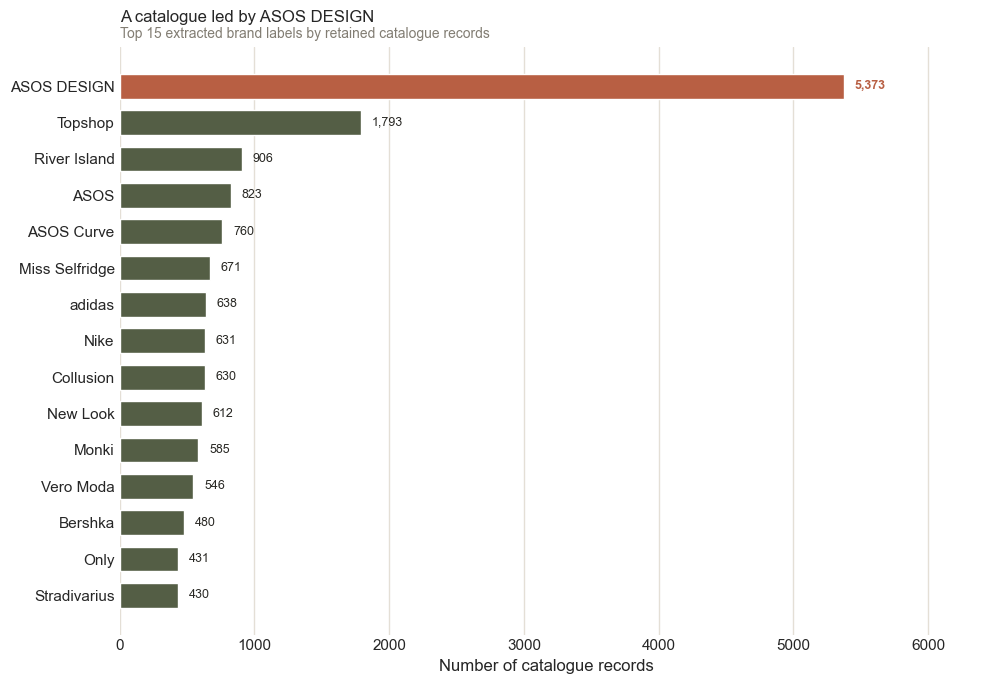

Top 10 labels: 12,837 records (42.8% of retained records)
Largest label: ASOS DESIGN (5,373; 17.9%)


,brand,record_count,catalogue_share_pct,cumulative_share_pct
0,ASOS DESIGN,5373,17.92,17.92
1,Topshop,1793,5.98,23.89
2,River Island,906,3.02,26.92
3,ASOS,823,2.74,29.66
4,ASOS Curve,760,2.53,32.19
5,Miss Selfridge,671,2.24,34.43
6,adidas,638,2.13,36.56
7,Nike,631,2.10,38.66
8,Collusion,630,2.10,40.76
9,New Look,612,2.04,42.80


In [191]:
brand_counts = (
    df_analysis["brand_clean"].dropna().value_counts()
    .rename_axis("brand")
    .reset_index(name="record_count")
)
brand_counts["catalogue_share_pct"] = (
    brand_counts["record_count"] / len(df_analysis) * 100
)
brand_counts["cumulative_share_pct"] = brand_counts["catalogue_share_pct"].cumsum()

top_brands = brand_counts.head(15).sort_values("record_count")
fig, ax = plt.subplots(figsize=(10, 7))

bar_colors = [
    TERRACOTTA if brand == "ASOS DESIGN" else OLIVE
    for brand in top_brands["brand"]
]
bars = ax.barh(
    top_brands["brand"],
    top_brands["record_count"],
    color=bar_colors,
    height=0.68,
)

for bar, (_, row) in zip(bars, top_brands.iterrows()):
    is_leader = row["brand"] == "ASOS DESIGN"
    ax.text(
        bar.get_width() + max(top_brands["record_count"]) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f'{int(row["record_count"]):,}',
        va="center",
        fontsize=9,
        fontweight="bold" if is_leader else "normal",
        color=TERRACOTTA if is_leader else CHARCOAL,
    )

ax.set_title("A catalogue led by ASOS DESIGN", loc="left", pad=18)
ax.text(
    0, 1.015,
    "Top 15 extracted brand labels by retained catalogue records",
    transform=ax.transAxes,
    fontsize=10,
    color=MUTED,
)
ax.set_xlabel("Number of catalogue records")
ax.set_ylabel("")
ax.set_xlim(0, top_brands["record_count"].max() * 1.18)
ax.grid(axis="x", color=GRID, alpha=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig(VISUALS_DIR / "catalogue-concentration.png", dpi=250, bbox_inches="tight")
plt.show()

top10_count = int(brand_counts.head(10)["record_count"].sum())
top10_share = top10_count / len(df_analysis)

if not brand_counts.empty:
    leader = brand_counts.iloc[0]
    print(f"Top 10 labels: {top10_count:,} records ({top10_share:.1%} of retained records)")
    print(
        f"Largest label: {leader['brand']} "
        f"({int(leader['record_count']):,}; "
        f"{leader['record_count'] / len(df_analysis):.1%})"
    )

display(brand_counts.head(15).round(2))


## 5. Price positioning by brand

Each point represents a brand label with at least 30 retained records. The x-axis shows catalogue presence and the y-axis shows median listed price. This is a descriptive comparison, not a measure of brand performance or consumer demand.


In [192]:

# Rebuild price classification and numeric prices from the original price column
price_text = df_analysis["price"].astype("string").str.strip()

df_analysis["price_type"] = "Standard"
df_analysis.loc[
    price_text.str.match(r"(?i)^Now\b", na=False), "price_type"
] = "Sale"
df_analysis.loc[
    price_text.str.match(r"(?i)^From\b", na=False), "price_type"
] = "Starting price"
df_analysis.loc[price_text.isna() | price_text.eq(""), "price_type"] = "Missing"

# Extract the numeric amount, including values prefixed by "Now" or "From"
df_analysis["price_clean"] = pd.to_numeric(
    price_text.str.replace(",", "", regex=False).str.extract(
        r"(\d+(?:\.\d+)?)", expand=False
    ),
    errors="coerce"
).astype("Float64")

print("Total records:", f"{len(df_analysis):,}")
print("\nPrice types:")
print(df_analysis["price_type"].value_counts(dropna=False))
print("\nValid numeric prices:", f"{df_analysis['price_clean'].notna().sum():,}")
print("Missing numeric prices:", f"{df_analysis['price_clean'].isna().sum():,}")


Total records: 29,990

Price types:
price_type
Standard          17889
Sale              12029
Starting price       72
Name: count, dtype: int64

Valid numeric prices: 29,990
Missing numeric prices: 0


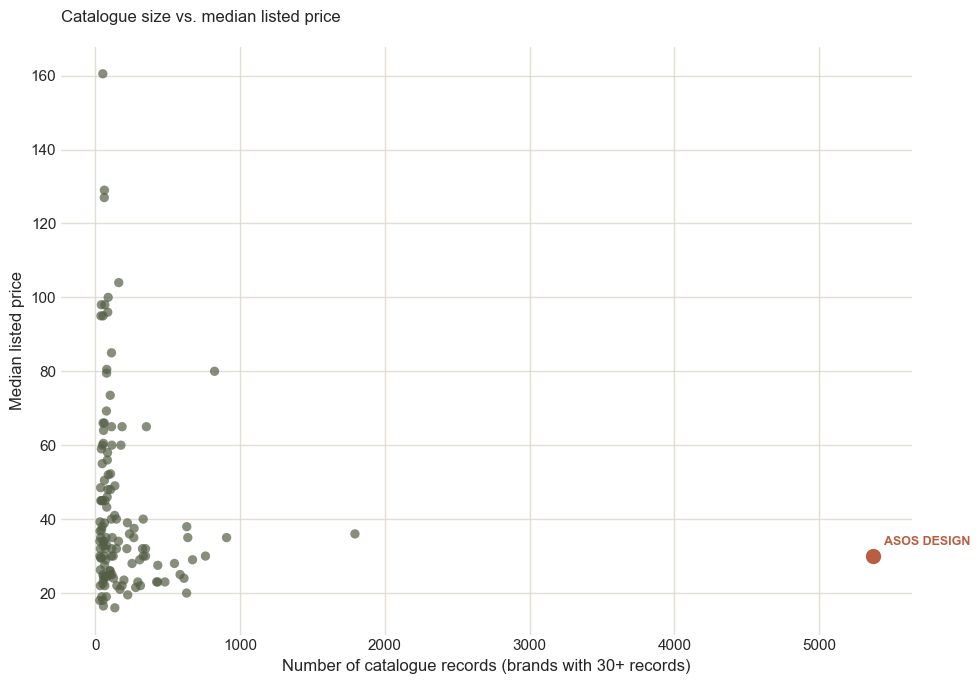

,brand,record_count,median_price
6,ASOS DESIGN,5373,30.0
180,Topshop,1793,36.0
150,River Island,906,35.0
3,ASOS,823,80.0
5,ASOS Curve,760,30.0
112,Miss Selfridge,671,29.0
204,adidas,638,35.0
127,Nike,631,37.95
37,Collusion,630,19.99
126,New Look,612,23.99


In [193]:
price_analysis = (
    df_analysis.dropna(subset=["brand_clean", "price_clean"])
    .groupby("brand_clean")
    .agg(
        record_count=("brand_clean", "size"),
        median_price=("price_clean", "median"),
    )
    .reset_index()
    .rename(columns={"brand_clean": "brand"})
)
price_analysis = price_analysis[price_analysis["record_count"] >= 30].copy()

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(
    price_analysis["record_count"],
    price_analysis["median_price"],
    color=OLIVE,
    alpha=0.7,
    s=45,
    edgecolors="none",
)

leader = price_analysis[price_analysis["brand"] == "ASOS DESIGN"]
if not leader.empty:
    ax.scatter(
        leader["record_count"],
        leader["median_price"],
        color=TERRACOTTA,
        s=100,
        zorder=3,
    )
    ax.annotate(
        "ASOS DESIGN",
        (leader["record_count"].iloc[0], leader["median_price"].iloc[0]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9,
        color=TERRACOTTA,
        fontweight="bold",
    )

ax.set_title("Catalogue size vs. median listed price", loc="left", pad=18)
ax.set_xlabel("Number of catalogue records (brands with 30+ records)")
ax.set_ylabel("Median listed price")
ax.grid(color=GRID, alpha=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "price-positioning.png", dpi=250, bbox_inches="tight")
plt.show()

display(price_analysis.sort_values("record_count", ascending=False).head(15).round(2))


## 6. Overall listed-price distribution

The histogram is capped at the 99th percentile for readability, while the summary statistics below use all successfully parsed prices.


,value
count,29990.0
mean,40.73
std,33.09
min,3.0
25%,21.0
50%,32.0
75%,49.0
90%,75.0
max,550.0


Records priced at 30 or below: 14,491 (48.3%)


,record_count,median_price,mean_price
price_type,,,
Sale,12029,25.0,31.52
Standard,17889,36.0,46.92
Starting price,72,29.5,40.33


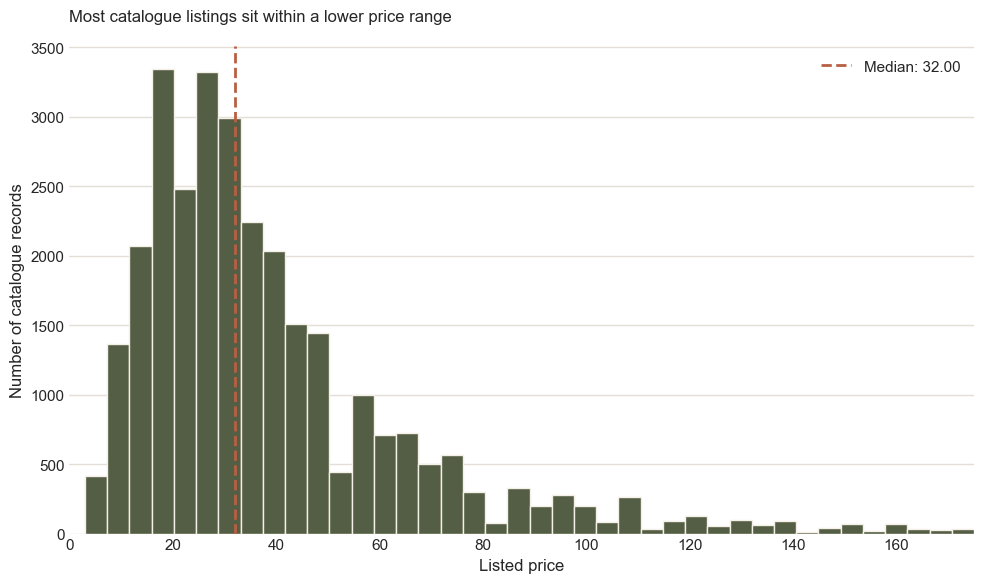

In [194]:
prices = df_analysis["price_clean"].dropna()
if prices.empty:
    raise ValueError("No valid prices were parsed. Review the price-cleaning step.")

display(
    prices.describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .round(2)
    .to_frame("value")
)
print(
    f"Records priced at 30 or below: "
    f"{(prices <= 30).sum():,} ({(prices <= 30).mean():.1%})"
)

display(
    df_analysis.groupby("price_type", dropna=False)
    .agg(
        record_count=("price_clean", "count"),
        median_price=("price_clean", "median"),
        mean_price=("price_clean", "mean"),
    )
    .round(2)
)

display_limit = prices.quantile(0.99)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(
    prices[prices <= display_limit],
    bins=40,
    color=OLIVE,
    edgecolor=IVORY,
)
ax.axvline(
    prices.median(),
    color=TERRACOTTA,
    linewidth=2,
    linestyle="--",
    label=f"Median: {prices.median():.2f}",
)
ax.set_xlim(0, display_limit)
ax.set_title("Most catalogue listings sit within a lower price range", loc="left", pad=18)
ax.set_xlabel("Listed price")
ax.set_ylabel("Number of catalogue records")
ax.grid(axis="y", color=GRID, alpha=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "price-distribution.png", dpi=250, bbox_inches="tight")
plt.show()


In [195]:

print("Total records:", len(df_analysis))
print("\nOriginal price examples:")
display(df_analysis[["price", "price_clean"]].head(15))

print("\nPrice types:")
print(df_analysis["price_type"].value_counts(dropna=False))

print("\nMissing cleaned prices:", df_analysis["price_clean"].isna().sum())


Total records: 29990

Original price examples:


,price,price_clean
0,49.99,49.99
4,59.99,59.99
8,45,45.0
10,84.95,84.95
14,75,75.0
18,56,56.0
21,40,40.0
25,38,38.0
29,40,40.0
33,150,150.0



Price types:
price_type
Standard          17889
Sale              12029
Starting price       72
Name: count, dtype: int64

Missing cleaned prices: 0


## 7. Summary and exported visuals

**Interpretation guardrails**
- Catalogue record counts are not sales, revenue, market share, or demand.
- Listed prices are descriptive snapshots; the data does not reliably support discount-depth calculations.
- Brand extraction is rule-based and should be treated as an estimate.
- Availability analysis has been removed from this version and is not part of the project conclusions.


In [196]:
summary = {
    "Source rows": source_rows,
    "Blank records excluded": source_rows - rows_after_blank_removal,
    "Repeated analytical records removed": rows_after_blank_removal - len(df_analysis),
    "Retained catalogue records": len(df_analysis),
    "Matched brand records": matched_count,
    "Unmatched brand records": unmatched_count,
    "Brand extraction coverage (%)": round(coverage * 100, 1),
    "Top 10 labels share of retained records (%)": round(top10_share * 100, 1),
    "Largest extracted label": brand_counts.iloc[0]["brand"] if not brand_counts.empty else None,
    "Largest label record count": int(brand_counts.iloc[0]["record_count"]) if not brand_counts.empty else 0,
    "Median listed price": round(prices.median(), 2) if not prices.empty else np.nan,
    "Mean listed price": round(prices.mean(), 2) if not prices.empty else np.nan,
    "Records priced at 30 or below (%)": round((prices <= 30).mean() * 100, 1) if not prices.empty else np.nan,
}
display(pd.Series(summary, name="value").to_frame())

print("Core charts exported:")
for filename in [
    "catalogue-concentration.png",
    "price-positioning.png",
    "price-distribution.png",
]:
    path = VISUALS_DIR / filename
    print(f"- {path.as_posix()}" if path.exists() else f"- {path.as_posix()} (created when chart cells run)")


,value
Source rows,30845
Blank records excluded,18
Repeated analytical records removed,837
Retained catalogue records,29990
Matched brand records,29419
Unmatched brand records,571
Brand extraction coverage (%),98.1
Top 10 labels share of retained records (%),42.8
Largest extracted label,ASOS DESIGN
Largest label record count,5373


Core charts exported:
- visuals/catalogue-concentration.png
- visuals/price-positioning.png
- visuals/price-distribution.png
